In [8]:
# Download SAM
!wget -q -N https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth

Loading weights:   0%|          | 0/978 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

/tmp/ipykernel_40600/1636165451.py:52: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  depth_map = np.array(depth_output["predicted_depth"])


Distance: 
object [1] - A PEDESTRIAN: relative proximity = 10.30


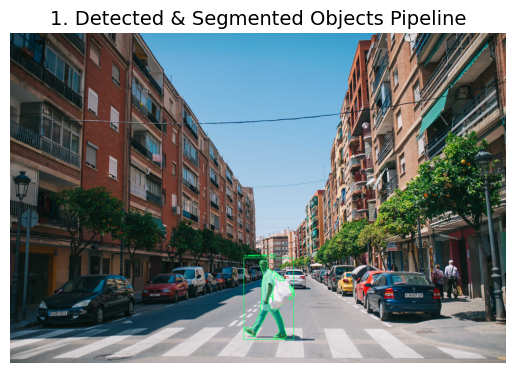

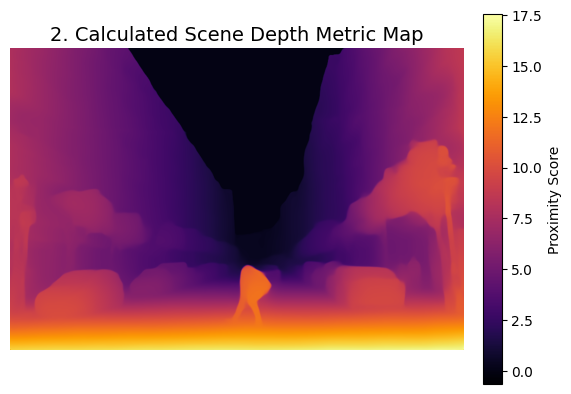

In [6]:
import cv2
import numpy as np
import requests
import torch
from PIL import Image
from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection, pipeline
import matplotlib.pyplot as plt
from segment_anything import sam_model_registry, SamPredictor

device = "cuda" if torch.cuda.is_available() else "cpu"




dino_id = "IDEA-Research/grounding-dino-tiny"
processor = AutoProcessor.from_pretrained(dino_id)
dino_model = AutoModelForZeroShotObjectDetection.from_pretrained(dino_id).to(device)



sam = sam_model_registry["vit_b"](checkpoint="sam_vit_b_01ec64.pth").to(device)
sam_predictor = SamPredictor(sam)


depth_estimator = pipeline(task="depth-estimation", model="LiheYoung/depth-anything-small-hf", device=device)


image_pil = Image.open("images/input_image.jpg")

img_np = np.array(image_pil)



text_labels = [["a pedestrian"]]

inputs = processor(images=image_pil, 
                   text=text_labels, 
                   return_tensors="pt").to(device)

with torch.no_grad():
    outputs = dino_model(**inputs)

result = processor.post_process_grounded_object_detection(
    outputs, inputs.input_ids, 
    threshold=0.4, 
    text_threshold=0.3, 
    target_sizes=[image_pil.size[::-1]]
)[0]


depth_output = depth_estimator(image_pil)
depth_map = np.array(depth_output["predicted_depth"])
depth_map = cv2.resize(depth_map, (img_np.shape[1], img_np.shape[0]))


sam_predictor.set_image(img_np)
final_display = img_np.copy()

colors = [(0, 255, 100), (100, 50, 200), (30, 100, 200)]

print("Distance: ")

for idx, (box, score, label) in enumerate(zip(result["boxes"], result["scores"], result["labels"])):
    bbox_dino = box.cpu().numpy()
    xmin, ymin, xmax, ymax = map(int, bbox_dino)
    current_color = colors[idx % len(colors)]
    
   
    masks, _, _ = sam_predictor.predict(
        point_coords=None, 
        point_labels=None, 
        box=bbox_dino[None, :], 
        multimask_output=False
    )
    object_mask = masks[0]

    
    
    object_depths = depth_map[object_mask]
    avg_proximity = np.mean(object_depths)

    
    print(f"object [{idx+1}] - {label.upper()}: relative proximity = {avg_proximity:.2f}")
    

    overlay_layer = final_display.copy()
    overlay_layer[object_mask] = current_color
    cv2.addWeighted(overlay_layer, 0.25, final_display, 0.75, 0, dst=final_display)
    
    contours, _ = cv2.findContours(object_mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(final_display, contours, -1, current_color, thickness=2)
    
    cv2.rectangle(final_display, (xmin, ymin), (xmax, ymax), current_color, 2)
    label_string = f"{label} (Dist: {avg_proximity:.1f})"
    cv2.putText(final_display, label_string, (xmin + 5, ymin - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.45, current_color, 2)




fig1, ax1 = plt.subplots()
ax1.imshow(final_display)
ax1.set_title("1. Detected & Segmented Objects Pipeline", fontsize=14)
ax1.axis("off")

fig2, ax2 = plt.subplots()
im_depth = ax2.imshow(depth_map, cmap="inferno")
ax2.set_title("2. Calculated Scene Depth Metric Map", fontsize=14)
ax2.axis("off")
fig2.colorbar(im_depth, ax=ax2, fraction=0.046, pad=0.04, label="Proximity Score")

# Save each figure separately
fig1.savefig("results/detected_and_segmented.png", dpi=300, bbox_inches="tight")
fig2.savefig("results/depth_map.png", dpi=300, bbox_inches="tight")

plt.show()